In [1]:
import pandas as pd
import numpy as np
import json
import os

In [2]:
# read metadata
metadata = pd.read_csv("../../data/new_data/combined_metadata_merged.tsv", sep="\t")

In [3]:
metadata.head()

,sample_name,season,host_subject_id,maggots,megyesi_score,sample_type,days_since_placement,body_site,add_0c,facility,project,dataset_type,env,bi_month,bi_month_name
0,14989.skin.face.SHSU.2016.024.2016.04.16.day2,spring,shsu.2016.024,eggs,9,skin,1,skin.face,23.333333,STAFS,PMI3,train,outdoor,2,Mar-Apr
1,14989.skin.hip.SHSU.2016.024.2016.04.16.day2,spring,shsu.2016.024,eggs,9,skin,1,skin.hip,23.333333,STAFS,PMI3,train,outdoor,2,Mar-Apr
2,14989.skin.face.UTK.K016.02.2016.04.16.day4,spring,UTK.K016.02,First inostar onolyes ino nosrils; oviposition...,3,skin,3,skin.face,51.388889,ARF,PMI3,train,outdoor,2,Mar-Apr
3,14989.skin.hip.UTK.K016.02.2016.04.16.day4,spring,UTK.K016.02,First inostar onolyes ino nosrils; oviposition...,3,skin,3,skin.hip,51.388889,ARF,PMI3,train,outdoor,2,Mar-Apr
4,14989.skin.face.CMU.16.03.2016.02.25.day1,spring,CMU_Mrs._16_03,no,3,skin,0,skin.face,0.000000,FIRS,PMI3,train,outdoor,2,Mar-Apr


In [ ]:
## read results
results_dir = "../results/hyperparam_search_D15_50trials/trial_16/val_predictions.json"


dict_keys(['14989.skin.face.SHSU.2016.007.2016.05.03.day19', '14989.skin.face.SHSU.2016.007.2016.04.21.day7', '14989.skin.face.SHSU.2016.007.2016.04.23.day9', '14989.skin.face.SHSU.2016.007.2016.05.04.day20', '14989.skin.face.SHSU.2016.007.2016.04.24.day10', '14989.skin.face.SHSU.2016.007.2016.05.05.day21', '14989.skin.face.SHSU.2016.007.2016.04.25.day11', '14989.skin.face.SHSU.2016.007.2016.04.17.day3', '14989.skin.face.SHSU.2016.007.2016.04.16day2', '14989.skin.face.SHSU.2016.007.2016.04.26.day12', '14989.skin.face.SHSU.2016.007.2016.04.19.day5', '14989.skin.face.SHSU.2016.007.2016.04.20.day6', '14989.skin.face.SHSU.2016.007.2016.04.28.day14', '14989.skin.face.SHSU.2016.007.2016.04.22.day8', '14989.skin.face.SHSU.2016.007.2016.04.29.day15', '14989.skin.hip.SHSU.2016.007.2016.04.21.day7', '14989.skin.face.SHSU.2016.007.2016.05.01.day17', '14989.skin.hip.SHSU.2016.007.2016.04.22.day8', '14989.skin.face.SHSU.2016.007.2016.05.02.day18', '14989.skin.hip.SHSU.2016.007.2016.04.23.day9', '14

In [5]:
sample_to_donor = dict(zip(metadata["sample_name"], metadata["host_subject_id"]))

In [15]:
## get per donor predictions and true values
def get_donor_to_preds(results_dir, sample_to_donor):
    with open(results_dir, "r") as f:
        results = json.load(f)

    donor_to_preds = {}
    for sample_name, (pred, true) in results.items():
        donor_id = sample_to_donor.get(sample_name)
        if donor_id is not None:
            if donor_id not in donor_to_preds:
                donor_to_preds[donor_id] = {"preds": [], "trues": []}
            donor_to_preds[donor_id]["preds"].append(pred)
            donor_to_preds[donor_id]["trues"].append(true)

    per_donor_mae = {}
    for donor_id, values in donor_to_preds.items():
        preds = np.array(values["preds"]) * 100
        trues = np.array(values["trues"]) * 100
        mae = np.mean(np.abs(preds - trues))
        per_donor_mae[donor_id] = mae   
    return per_donor_mae

In [20]:
best_res = get_donor_to_preds(results_dir, sample_to_donor)
best_res, np.mean(list(best_res.values()))

({'shsu.2016.007': 36.7942644490136,
  '2016.067': 73.55918623507023,
  'Mr 17-04': 51.973739080131054,
  'UTK.K016.06': 49.52752715662906,
  'D10': 35.02857669805869,
  'D5': 35.20486232112436,
  'FROST_Body2': 49.64465053663368},
 47.39040092523724)

In [23]:
res = get_donor_to_preds("../results/all_data_abundance_proj_notanh_grl_ST2/D15/run_1/val_predictions.json", sample_to_donor)
res, np.mean(list(res.values()))

({'shsu.2016.007': 36.03061714933978,
  '2016.067': 62.34920769929886,
  'Mr 17-04': 44.01576487580314,
  'UTK.K016.06': 65.40517791321403,
  'D10': 31.945418967650486,
  'D5': 27.049584862063913,
  'FROST_Body2': 64.10215369292668},
 47.2711321657567)

In [25]:
res2 = get_donor_to_preds("../results/all_data_abundance_proj_notanh_grl_ST2/D15/run_2/val_predictions.json", sample_to_donor)
res2, np.mean(list(res2.values()))

({'shsu.2016.007': 33.00942492981752,
  '2016.067': 79.3852358435591,
  'Mr 17-04': 52.71085831336677,
  'UTK.K016.06': 48.84523514070009,
  'D10': 33.9293224689288,
  'D5': 35.74476686908918,
  'FROST_Body2': 67.66367891714687},
 50.184074640372614)

In [2]:
##### splits generated by trpca 
skin_data_json = "../../TRPCA/2_trails_results/group_assignments_skin_data.json"
skin_metadata = "../../age-prediction/Input/skin_data/skin_1975_map.txt"


In [ ]:
oral_data_json = "../../TRPCA/2_trails_results/group_assignments_oral_data.json"
oral_metadata = "../../age-prediction/Input/oral_data/oral_2550_map.txt"

In [14]:
with open(oral_data_json, "r") as f:
    oral_trpca_groups = json.load(f)
oral_metadata_df = pd.read_csv(oral_metadata, sep="\t")

/tmp/ipykernel_1701037/1696919415.py:3: DtypeWarning: Columns (87,280,391,626,660,661,760,761,763,764,765,766,767,768,769,806,809,933) have mixed types. Specify dtype option on import or set low_memory=False.
  oral_metadata_df = pd.read_csv(oral_metadata, sep="\t")


In [3]:
with open(skin_data_json, "r") as f:
    trpca_splits = json.load(f)

skin_metadata_df = pd.read_csv(skin_metadata, sep="\t")

/tmp/ipykernel_1701037/498073787.py:4: DtypeWarning: Columns (124,384,841,844,968) have mixed types. Specify dtype option on import or set low_memory=False.
  skin_metadata_df = pd.read_csv(skin_metadata, sep="\t")


In [15]:
oral_metadata_df.head()

,#SampleID,achilles_tendinitis,acid_reflux,acne,acne_medication,acne_medication_otc,acute_kidney_failure,acute_liver_failure,add_adhd,adequacycalsen_class,...,qiita_host_ethnicity_hispanic_or_latino,qiita_host_ethnicity_asian,qiita_host_ethnicity_native_hawaiian_or_other_pacific_islander,qiita_host_ethnicity_other,qiita_host_ethnicity_combined,age_groups,X_sample_id,X_calour_original_abundance,Adult,study_id
0,11052.3.20.13.rk.t,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,False,False,False,False,NaN,30s,11052.3.20.13.rk.t,97785,True,11052
1,10317.000003639,NaN,NaN,NaN,False,False,NaN,NaN,NaN,NaN,...,False,True,False,False,white,50s,10317.000003639,34517,True,10317
2,550.L6S136.s.6.sequence,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,False,False,False,False,NaN,30s,550.L6S136.s.6.sequence,33763,True,550
3,10317.000031067,NaN,NaN,NaN,False,False,NaN,NaN,NaN,NaN,...,False,True,False,False,white,40s,10317.000031067,7378,True,10317
4,11052.3.28.14.rk.t,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,False,False,False,False,NaN,30s,11052.3.28.14.rk.t,97432,True,11052


In [5]:

train_metadata = skin_metadata_df[skin_metadata_df["#SampleID"].isin(trpca_splits["train_indices"])]
test_metadata = skin_metadata_df[skin_metadata_df["#SampleID"].isin(trpca_splits["test_indices"])]

In [16]:

train_metadata = oral_metadata_df[oral_metadata_df["#SampleID"].isin(oral_trpca_groups["train_indices"])]
test_metadata = oral_metadata_df[oral_metadata_df["#SampleID"].isin(oral_trpca_groups["test_indices"])]

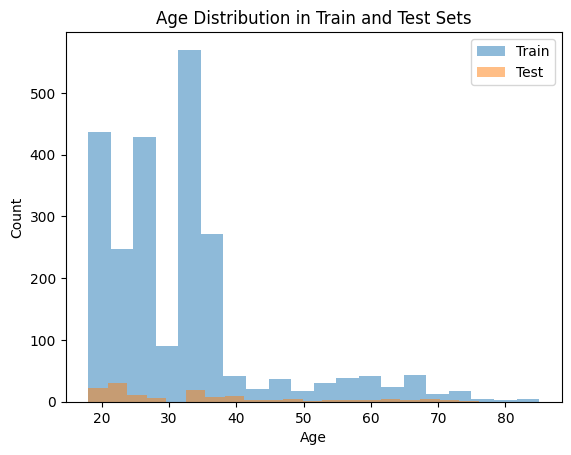

In [17]:
### plot age distribution in train and test
import matplotlib.pyplot as plt 
plt.hist(train_metadata["qiita_host_age"], bins=20, alpha=0.5, label="Train")
plt.hist(test_metadata["qiita_host_age"], bins=20, alpha=0.5, label="Test")
plt.xlabel("Age")
plt.ylabel("Count")
plt.legend()
plt.title("Age Distribution in Train and Test Sets")
plt.show()

In [18]:
# overlap between train and test donors
train_donors = set(train_metadata["host_subject_id"])
test_donors = set(test_metadata["host_subject_id"])
overlap_donors = train_donors.intersection(test_donors)
print(f"Number of donors in train set: {len(train_donors)}")
print(f"Number of donors in test set: {len(test_donors)}")
print(f"Number of overlapping donors: {len(overlap_donors)}")

Number of donors in train set: 629
Number of donors in test set: 70
Number of overlapping donors: 0


In [19]:
val_indices = []
with open("../results/age_prediction/oral_data/rel_abundanceeee_works_grouped/seed_100/val_indices.txt", "r") as f:
    for line in f.readlines():
        val_indices.append(line.strip())



In [9]:
val_indices = []
with open("../results/age_prediction/skin_data/rel_abundanceeee_works_l1/seed_100/val_indices.txt", "r") as f:
    for line in f:
        val_indices.append(line.strip())

In [20]:
set(train_metadata["#SampleID"]) & set(val_indices)

{'10052.MG.O12',
 '10052.MG.O5',
 '10052.MG.O50',
 '10317.000002049',
 '10317.000002383',
 '10317.000002491',
 '10317.000002532',
 '10317.000002608',
 '10317.000002771',
 '10317.000002841',
 '10317.000002842',
 '10317.000003027',
 '10317.000003131',
 '10317.000003321',
 '10317.000003557',
 '10317.000004062',
 '10317.000004953',
 '10317.000005087',
 '10317.000005575',
 '10317.000005842',
 '10317.000005921',
 '10317.000006679',
 '10317.000006975',
 '10317.000007043',
 '10317.000007125',
 '10317.000009072',
 '10317.000009076',
 '10317.000009081',
 '10317.000009367',
 '10317.000009756',
 '10317.000010977',
 '10317.000013358',
 '10317.000013865',
 '10317.000013886',
 '10317.000013887',
 '10317.000014193',
 '10317.000015213',
 '10317.000015225',
 '10317.000015251',
 '10317.000015362',
 '10317.000015975',
 '10317.000017317',
 '10317.000017757',
 '10317.000018077',
 '10317.000020766',
 '10317.000022131',
 '10317.000022373',
 '10317.000023039',
 '10317.000023666',
 '10317.000023875',
 '10317.00

In [21]:
val_metadata = train_metadata[train_metadata["#SampleID"].isin(val_indices)]
train_metadata_no_val = train_metadata[~train_metadata["#SampleID"].isin(val_indices)]



In [22]:
val_donors = set(oral_metadata_df[oral_metadata_df["#SampleID"].isin(val_indices)]["host_subject_id"])
train_donors = set(train_metadata_no_val["host_subject_id"])
test_donors = set(test_metadata["host_subject_id"])
print(f"Number of donors in validation set: {len(val_donors)}")
print(f"Number of overlapping donors between train and validation sets: {len(train_donors.intersection(val_donors))}")
print(f"Number of overlapping donors between test and validation sets: {len(test_donors.intersection(val_donors))}")

Number of donors in validation set: 94
Number of overlapping donors between train and validation sets: 5
Number of overlapping donors between test and validation sets: 0


In [32]:
overlapping = train_donors.intersection(val_donors)

In [33]:
val_metadata[val_metadata["host_subject_id"].isin(overlapping)]

,#SampleID,achilles_tendinitis,acid_reflux,acne,acne_medication,acne_medication_otc,acute_kidney_failure,acute_liver_failure,add_adhd,adequacycalsen_class,...,qiita_host_ethnicity_hispanic_or_latino,qiita_host_ethnicity_asian,qiita_host_ethnicity_native_hawaiian_or_other_pacific_islander,qiita_host_ethnicity_other,qiita_host_ethnicity_combined,age_groups,X_sample_id,X_calour_original_abundance,Adult,study_id
73,2010.2379,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,True,False,False,False,mestizo,20s,2010.2379,12827,True,2010
147,2024.visit2.MNIH86NP.BFC10H.O,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,False,False,False,False,NaN,20s,2024.visit2.MNIH86NP.BFC10H.O,11758,True,2024
435,2010.2317,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,True,False,False,False,mestizo,20s,2010.2317,6920,True,2010
553,2024.final.MNIH86NP.BFG111.O,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,False,False,False,False,NaN,20s,2024.final.MNIH86NP.BFG111.O,5176,True,2024
648,2010.2234,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,True,False,False,False,mestizo,20s,2010.2234,6714,True,2010
1012,2010.2214,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,True,False,False,False,mestizo,20s,2010.2214,34350,True,2010
1097,2024.visit1.MNIH86NP.BFB10Z.O,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,False,False,False,False,NaN,20s,2024.visit1.MNIH86NP.BFB10Z.O,10828,True,2024
1291,2024.final.MNIH58N.BFG101.O,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,False,False,False,False,NaN,10s,2024.final.MNIH58N.BFG101.O,9467,True,2024
1551,2010.2243,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,True,False,False,False,mestizo,20s,2010.2243,9482,True,2010
1741,10317.000072331,NaN,I do not have this condition,NaN,False,False,NaN,NaN,I do not have this condition,NaN,...,True,False,False,False,hispanic,40s,10317.000072331,17231,True,10317


In [31]:
oral_metadata_df[oral_metadata_df["host_subject_id"] == "MNIH86NP"]["qiita_host_age"]

147     25.0
553     25.0
1097    25.0
1494    25.0
1895    25.0
2524    25.0
Name: qiita_host_age, dtype: float64

In [34]:
val_metadata["qiita_host_age"].describe(), test_metadata["qiita_host_age"].describe()

(count    171.000000
 mean      32.777778
 std       16.363797
 min       18.000000
 25%       20.000000
 50%       25.000000
 75%       39.000000
 max       84.000000
 Name: qiita_host_age, dtype: float64,
 count    136.000000
 mean      33.801471
 std       15.266919
 min       18.000000
 25%       22.000000
 50%       29.000000
 75%       40.250000
 max       76.000000
 Name: qiita_host_age, dtype: float64)

In [10]:
test_metadata["cohort"].value_counts(), test_metadata["sex"].value_counts()

(cohort
 AGP          284
 cantonese    154
 Name: count, dtype: int64,
 sex
 female    251
 male      187
 Name: count, dtype: int64)

In [ ]:
### random splits 
import random
random_seed = 42
test_split = 0.2
random.seed(random_seed)
shuffled = list(gut_metadata_df["#SampleID"])
random.shuffle(shuffled)
sample_ids = shuffled
# Split sample IDs into train and test

train_idx  = int(len(sample_ids) * (1 - test_split))
val_start_idx = int(len(sample_ids) * (1 - test_split))
val_end_idx = int(len(sample_ids) * (1 - test_split))

train_sample_ids = sample_ids[:int(len(sample_ids) * (1 - test_split))]
val_sample_ids = sample_ids[int(len(sample_ids) * (1 - test_split) * 0.5):int(len(sample_ids) * (1 - test_split))]
test_sample_ids = sample_ids[int(len(sample_ids) * (1 - test_split)):]


In [13]:
random_train_metadata = gut_metadata_df[gut_metadata_df["#SampleID"].isin(train_sample_ids)]
random_val_metadata = gut_metadata_df[gut_metadata_df["#SampleID"].isin(val_sample_ids)]
random_test_metadata = gut_metadata_df[gut_metadata_df["#SampleID"].isin(test_sample_ids)]


In [14]:
random_train_metadata["cohort"].value_counts(), random_train_metadata["sex"].value_counts()

(cohort
 AGP          2246
 cantonese    1301
 Name: count, dtype: int64,
 sex
 female    1973
 male      1530
 Name: count, dtype: int64)

In [16]:
random_test_metadata["cohort"].value_counts(), random_test_metadata["sex"].value_counts()

(cohort
 AGP          579
 cantonese    308
 Name: count, dtype: int64,
 sex
 female    489
 male      387
 Name: count, dtype: int64)

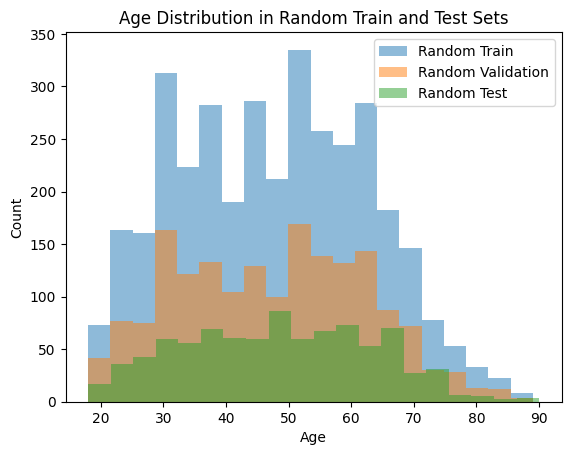

In [15]:
import matplotlib.pyplot as plt
plt.hist(random_train_metadata["age"], bins=20, alpha=0.5, label="Random Train")
plt.hist(random_val_metadata["age"], bins=20, alpha=0.5, label="Random Validation")
plt.hist(random_test_metadata["age"], bins=20, alpha=0.5, label="Random Test")
plt.xlabel("Age")
plt.ylabel("Count")
plt.legend()
plt.title("Age Distribution in Random Train and Test Sets")
plt.show()

In [17]:
train_metadata.shape, test_metadata.shape, random_train_metadata.shape, random_val_metadata.shape, random_test_metadata.shape

((3941, 10), (438, 10), (3547, 10), (1774, 10), (887, 10))

In [25]:
#overlap check 
set(val_sample_ids) & set(test_sample_ids)

set()

In [ ]:
len(sample_ids), int(len(sample_ids) * (1 - test_split)), 

(4434, 3547)

In [22]:
int(len(sample_ids) * (1 - test_split) * 0.5)

1773